# 2026.10.20(화) 20h~

In [ ]:
# %pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import numpy as np                         # 숫자 배열을 계산하는 도구
import matplotlib.pyplot as plt            # 숫자를 그래프로 보는 도구
from IPython.display import Audio, display # 노트북 안에 재생 버튼을 표시하는 도구
from pathlib import Path                   # 파일 위치를 표현하는 도구
import json                                # 작은 결과 기록을 저장하는 도구
import matplotlib.font_manager as fm

# 그래프에 한글을 표시합니다. 이 준비 코드는 수정하지 않고 실행합니다.
available_fonts = {font.name for font in fm.fontManager.ttflist}
for font_name in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if font_name in available_fonts:
        plt.rcParams["font.family"] = font_name
        break
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.figsize"] = (10, 3)
plt.rcParams["figure.dpi"] = 110

SR = 16000  # 이번 기초 실습의 기준: 1초에 16,000개 데이터가 필요함(전화 벨 소리 8천, CD/DVD는 4만 정도). 모든 모델의 공통 규격이라는 뜻은 아닙니다.
print("준비 완료 / 이번 실습의 SR:", SR)

준비 완료 / 이번 실습의 SR: 16000


## 섹션1. __

## 실습1: 숫자 9개를 읽고 그리기

In [ ]:
sound = np.array([0.0, 0.4, 0.8, 0.4, 0.0, -0.4, -0.8, -0.4, 0.0]) # 자료형 = numpy array
print("숫자 배열 sound:", sound)
print("sound의 자료형:", type(sound)) # <class 'numpy.ndarray'>
print("샘플 수:", len(sound))
print("배열 모양:", sound.shape)        # (9,)는 9개짜리 1차원 배열, 이 자료형 자체/배열 모양 반환 값은 tuple(외부에서 바꾸면 안 되는 값이니까)
print("첫 샘플:", sound[0])             # 번호는 0부터 시작
print("2번부터 4번까지:", sound[2:5])   # 2, 3, 4번의 값 3개

숫자 배열 sound: [ 0.   0.4  0.8  0.4  0.  -0.4 -0.8 -0.4  0. ]
sound의 자료형: <class 'numpy.ndarray'>
샘플 수: 9
배열 모양: (9,)
첫 샘플: 0.0
2번부터 4번까지: [0.8 0.4 0. ]


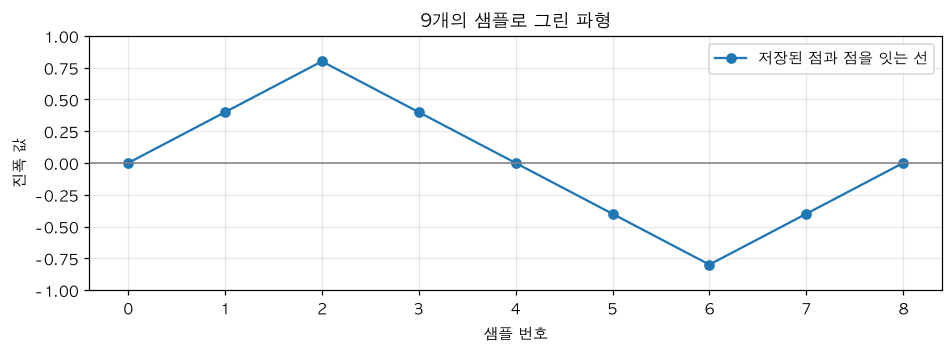

In [4]:
plt.figure()
plt.plot(sound, "o-", label="저장된 점과 점을 잇는 선")
plt.axhline(0, color="gray", linewidth=1)
plt.xlabel("샘플 번호")
plt.ylabel("진폭 값")
plt.title("9개의 샘플로 그린 파형")
plt.ylim(-1, 1)                         # 변경 전후 같은 세로축으로 비교
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 실습2. 원하는 값 찾기

In [5]:
print("마지막 샘플:", sound[-1])                 # 뒤에서 첫 번째
print("뒤에서 3개:", sound[-3:])                 # 뒤에서 세 번째부터 끝까지
print("가장 큰 값:", sound.max(), "/ 번호:", sound.argmax())
print("가장 작은 값:", sound.min(), "/ 번호:", sound.argmin())
print("0보다 큰 샘플 수:", (sound > 0).sum())
print("0보다 작은 샘플 수:", (sound < 0).sum())
print("정확히 0인 샘플 수:", (sound == 0).sum())

마지막 샘플: 0.0
뒤에서 3개: [-0.8 -0.4  0. ]
가장 큰 값: 0.8 / 번호: 2
가장 작은 값: -0.8 / 번호: 6
0보다 큰 샘플 수: 3
0보다 작은 샘플 수: 3
정확히 0인 샘플 수: 3


## 실습5.

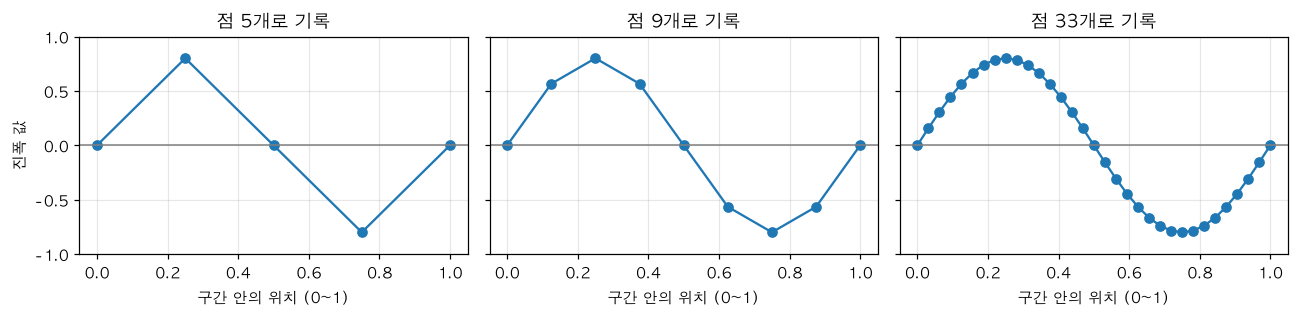

In [9]:
# [이 셀이 하는 일]
#  같은 "사인파 한 번 오르내림"을 점 5개 / 9개 / 33개로 기록했을 때 모양이 어떻게 달라지는지 나란히 비교한다.
#  -> 샘플(점)을 촘촘하게 찍을수록 원래의 부드러운 소리 파형에 가까워진다. (소리가 숫자가 되는 과정의 핵심)

# fig, axes = plt.subplots(행, 열, ...) : 그림 영역(fig) 하나와 그 안의 그래프 칸(axes)들을 한꺼번에 만든다.
#  - 1, 3        : 1행 3열 -> 그래프 칸 3개를 가로로 나란히 배치
#  - figsize=(12, 3) : 전체 그림 크기 (가로 12인치, 세로 3인치)
#  - sharey=True : 세 칸이 세로축(y축)의 범위와 눈금을 같이 쓴다. -> 칸마다 높이를 같은 기준으로 비교할 수 있음
#  - 반환값 : fig = 그림 전체, axes = 그래프 칸 3개가 든 배열 (axes[0], axes[1], axes[2]). 이 셀에서 fig는 따로 쓰지 않는다.
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)

# zip(axes, [5, 9, 33]) : 그래프 칸과 점 개수를 짝지어 한 쌍씩 꺼낸다.
#  -> (axes[0], 5), (axes[1], 9), (axes[2], 33)  => 반복이 3번 돌고, 칸마다 점 개수가 다르게 그려진다.
#  - ax       : 지금 그리고 있는 그래프 칸
#  - n_points : 이번 칸에서 사용할 점(샘플)의 개수
for ax, n_points in zip(axes, [5, 9, 33]):
    # np.linspace(0, 1, n_points) : 0부터 1까지를 "끝점 포함"해서 n_points개의 같은 간격 숫자로 만든다.
    #  예) n_points=5  -> [0, 0.25, 0.5, 0.75, 1]            (간격 0.25,   구간 4칸)
    #      n_points=9  -> [0, 0.125, 0.25, ..., 1]           (간격 0.125,  구간 8칸)
    #      n_points=33 -> [0, 0.031, 0.062, ..., 1]          (간격 약 0.031, 구간 32칸)
    #  여기서 position은 "한 번 오르내리는 구간 안에서의 위치(0~1)"이고, 가로축(x)이 된다. (실제 시간이 아님)
    #  점 개수가 n개면 점과 점 사이 구간은 n-1개다. (양 끝점 0과 1을 모두 포함하기 때문)
    position = np.linspace(0, 1, n_points)          # 한 번 오르내리는 구간을 n_points개 위치로 나눔

    # 0.8 * np.sin(2 * np.pi * position) : 각 위치에서의 소리 크기(진폭 값)를 계산한다. 순서대로 풀면
    #  1) 2 * np.pi * position : 위치 0~1을 각도 0~2π(라디안)로 바꾼다. 2π = 한 바퀴이므로 "사인파 한 주기"에 해당
    #  2) np.sin(...)           : 각도의 사인값. 0 -> 1(위 꼭대기) -> 0 -> -1(아래 꼭대기) -> 0 순서로 -1~1 사이를 오르내림
    #  3) 0.8 * ...             : 진폭(최대 높이)을 0.8로 줄임. 그래서 값은 -0.8 ~ 0.8 범위 (아래 plt.ylim(-1, 1) 안에 여유 있게 들어옴)
    #  numpy 배열 전체에 한 번에 계산이 적용되므로 for문 없이 n_points개의 값이 한꺼번에 나온다.
    #  참고: 마지막 점은 이론상 0이지만 컴퓨터 계산 오차 때문에 -1.96e-16처럼 0에 아주 가까운 값이 나온다 (그래프에서는 0으로 보임)
    values = 0.8 * np.sin(2 * np.pi * position)      # 각 위치의 높이

    # ax.plot(x값들, y값들, "o-") : 이 칸에 그래프를 그린다. 세 번째 인자 "o-"는 서식 문자열
    #  - "o" : 각 데이터 점을 동그라미로 표시   - "-" : 점과 점을 실선으로 이음   -> 합치면 "점 + 선" 그래프
    #  점 5개일 때는 (0, 0.8, 0, -0.8, 0)을 직선으로 이어서 뾰족한 지그재그처럼 보이고,
    #  33개일 때는 곡선처럼 부드럽게 보인다. => 점이 적으면 원래 소리 모양을 제대로 못 담는다.
    ax.plot(position, values, "o-")

    # ax.axhline(0, ...) : y=0 위치에 가로 기준선을 긋는다. (소리가 0을 기준으로 위아래로 흔들리는 것을 보기 쉽게)
    #  - color="gray" : 회색   - linewidth=1 : 선 굵기 1
    ax.axhline(0, color="gray", linewidth=1)

    # ax.set_title(...) : 이 칸의 제목. f"..." 문자열 안의 {n_points}가 실제 숫자(5, 9, 33)로 바뀐다. 예) "점 5개로 기록"
    ax.set_title(f"점 {n_points}개로 기록")

    # ax.set_xlabel(...) : 이 칸의 가로축 이름. 가로축 값 position(0~1)은 한 구간 안의 위치이다.
    ax.set_xlabel("구간 안의 위치 (0~1)")

    # ax.grid(alpha=0.3) : 격자선을 표시. alpha는 투명도(0=안 보임, 1=진함) -> 0.3으로 연하게 해서 데이터가 묻히지 않게 한다.
    ax.grid(alpha=0.3)

# --- 반복문이 끝난 뒤: 세 칸 공통 마무리 ---

# axes[0].set_ylabel(...) : 맨 왼쪽 칸에만 세로축 이름을 붙인다. (sharey=True라서 세 칸이 같은 세로축을 쓰므로 한 번만 써도 충분)
axes[0].set_ylabel("진폭 값")

# plt.ylim(-1, 1) : 세로축 범위를 -1~1로 고정한다.
#  plt.xxx는 "현재(가장 마지막) 칸"에 적용되는데, sharey=True로 세로축을 공유하므로 세 칸 모두 -1~1이 된다. (실행해서 확인)
plt.ylim(-1, 1)

# plt.tight_layout() : 칸끼리, 제목/축 이름끼리 글자가 겹치지 않게 간격을 자동으로 조정한다.
plt.tight_layout()

# plt.show() : 그린 그림을 화면(노트북 출력)에 표시한다.
plt.show()


### Q. 진폭이 뭐야? 주파수와 관계가 있는 개념이야?

**한 줄 답: 진폭은 "얼마나 크게 흔들리나"(소리의 세기), 주파수는 "얼마나 빠르게 흔들리나"(소리의 높낮이)입니다. 둘 다 사인파를 설명하는 숫자지만 서로 독립이라서, 하나를 바꿔도 다른 하나는 그대로입니다.**

#### 1. 진폭 (Amplitude)
- 파형이 **기준선(0)에서 위아래로 얼마나 멀리 가는지**, 즉 파도의 **높이**입니다.
- 소리에서는 **소리의 세기(크기)** 에 해당합니다. 진폭이 클수록 큰 소리, 작을수록 작은 소리입니다. (소리 크기를 사람이 느끼는 정도는 진폭에 정확히 비례하지는 않습니다. 이 부분은 제 배경 지식이고 이 노트북에서 다루는 내용은 아닙니다.)
- 위 코드의 `0.8 * np.sin(...)`에서 **0.8이 진폭**입니다. `np.sin`은 원래 -1~1 사이를 오가므로, 0.8을 곱하면 -0.8~0.8 사이를 오갑니다. 그래프 세로축의 "진폭 값"이 바로 이것입니다.
- 이 노트북의 `sound` 배열(`[0.0, 0.4, 0.8, 0.4, 0.0, -0.4, -0.8, ...]`)에서는 가장 큰 값 0.8이 이 파형의 진폭(최대 높이)입니다.

#### 2. 주파수 (Frequency)
- **1초에 파형이 몇 번 반복(진동)하는지**입니다. 단위는 **Hz(헤르츠)**. 440 Hz = 1초에 440번 오르내림.
- 소리에서는 **음의 높낮이(음높이)** 에 해당합니다. 주파수가 높을수록 높은 음(예: 아기 울음소리), 낮을수록 낮은 음(예: 북소리)입니다.
- 위 코드에서는 `2 * np.pi * position`이 "한 바퀴(한 번 오르내림)"를 만들어서, **구간 안에서 딱 한 번만** 오르내립니다. 주파수를 바꾸려면 이 부분에 배수를 곱하면 됩니다 (아래 3절).

#### 3. 한 식에서 두 가지를 모두 볼 수 있습니다
```text
y = A · sin(2π · f · t)
    └ A: 진폭(높이)      └ f: 주파수(1초에 몇 번 반복)   t: 시간
```

| 바꾸는 것 | 파형에서 달라지는 점 | 소리로는 |
|---|---|---|
| **A**(진폭) ↑ | 위아래로 **더 높이** 흔들림 (모양은 같고 키만 커짐) | 더 **큰** 소리 |
| **f**(주파수) ↑ | **더 촘촘하게** 반복 (높이는 같음) | 더 **높은** 음 |

실행해서 확인한 값 (점 9개, 위치 0~1 구간):
```text
A=0.8, f=1 : [0, 0.566, 0.8, 0.566, 0, -0.566, -0.8, -0.566, 0]      ← 기본 (한 번 오르내림)
A=0.4, f=1 : [0, 0.283, 0.4, 0.283, 0, -0.283, -0.4, -0.283, 0]      ← 진폭만 절반: 모양 같고 최대값 0.4
A=0.8, f=2 : [0, 0.8,   0, -0.8,   0,  0.8,   0, -0.8,   0]          ← 주파수만 2배: 같은 구간에서 두 번 오르내림
```

직접 확인하려면 아래 셀을 실행해 보세요.
```python
position = np.linspace(0, 1, 200)           # 점을 촘촘히 찍어 곡선이 보이게
for A, f in [(0.8, 1), (0.4, 1), (0.8, 2)]:
    plt.plot(position, A * np.sin(2 * np.pi * f * position), label=f"진폭 {A}, 주파수 {f}")
plt.axhline(0, color="gray", linewidth=1)
plt.legend()
plt.show()
```

#### 4. 그럼 "관계 있는 개념"인가? 정리
- **서로 다른 개념, 서로 독립**: 큰 소리인데 낮은 음일 수도, 작은 소리인데 높은 음일 수도 있습니다.
- **같이 쓰이는 이유**: 사인파는 이 둘(+ 시작 위치인 위상)만 정하면 완전히 정해지기 때문입니다. 실제 소리는 여러 주파수의 사인파가 각자 다른 진폭으로 섞인 것이고, 이후 FFT·스펙트로그램에서 **"어떤 주파수가 얼마만큼(진폭) 들어 있는가"** 를 보게 됩니다. (앞으로 배울 내용이라 이 노트북에서는 다루지 않았고, 이 연결은 일반적인 설명입니다.)
- **헷갈리기 쉬운 것 — 주파수 vs SR**: 바로 아래 표에 있듯이 단위는 둘 다 Hz지만 **주파수 = 소리가 진동하는 횟수, SR = 컴퓨터가 기록하는 횟수**입니다. 예를 들어 440 Hz 소리를 SR 16000으로 기록하면 한 번 오르내림(한 주기)을 약 `16000 ÷ 440 ≈ 36.4`개의 샘플로 표현합니다.

| 한 주기를 기록하는 샘플 수 (SR=16000) | 계산 |
|---|---|
| 100 Hz → 160개 | 16000 ÷ 100 |
| 440 Hz → 약 36.4개 | 16000 ÷ 440 |
| 1000 Hz → 16개 | 16000 ÷ 1000 |
| 8000 Hz → **2개** | 16000 ÷ 8000 |

- 주파수가 높을수록 한 주기에 쓸 수 있는 샘플이 적어져서 **파형 모양을 제대로 담기 어렵습니다.** 위 5개/9개/33개 비교 그래프에서 본 "점이 적으면 부드러운 곡선이 지그재그로 보인다"는 현상과 같은 원리입니다. (SR의 절반(여기서는 8000 Hz)이 담을 수 있는 한계라는 이야기는 이후에 배울 표본화 정리와 연결되는 내용이며, 이번 노트북 범위 밖입니다.)

---

### 추가 질문 1. 큰 소리 = forte, 작은 소리 = pianissimo 같은 개념인가? (악상 기호와 진폭)

**네, 같은 쪽 개념입니다.** 악상 기호(셈여림표)는 "얼마나 크게/작게 연주하라"를 말하고, 그 **소리의 크기가 파형에서는 진폭**으로 나타납니다.

| 악상 기호 | 뜻 | 파형에서는 (대략) |
|---|---|---|
| **pp** pianissimo | 아주 여리게 | 진폭이 아주 작음 |
| **p** piano | 여리게 | 진폭이 작음 |
| **f** forte | 세게 | 진폭이 큼 |
| **ff** fortissimo | 아주 세게 | 진폭이 아주 큼 |

- 기호 하나하나가 "진폭 0.3" 같은 **정해진 숫자를 뜻하지는 않습니다.** 연주자, 악기, 곡마다 상대적인 기준입니다. (예: 같은 곡 안에서 p보다 f가 더 크다)
- 같은 계단(예: 도를 p로 치다가 f로 치기)에서 **음높이(주파수)는 그대로이고 크기(진폭)만 달라집니다.** 위 3절 표의 "A만 바꾸면 모양은 같고 키만 커짐"과 같은 상황입니다.
- 참고(일반 지식, 이 노트북에서 확인하지는 않음): 실제 악기는 세게 칠수록 단순히 크기만 커지지 않고 소리의 색깔(음색)도 조금 달라집니다. 사인파 하나로 만든 소리는 진폭만 바뀌는 가장 단순한 경우입니다.

---

### 추가 질문 2. "낮은 음"은 무슨 뜻인가? (피아노 건반, 높은음자리표·낮은음자리표의 도)

**"낮은 음 = 주파수가 낮은 소리"입니다. 피아노 건반에서는 왼쪽으로 갈수록 낮은 음(주파수 낮음), 오른쪽으로 갈수록 높은 음(주파수 높음)입니다.**

```
 낮은 음 ◀────────── 피아노 건반 ──────────▶ 높은 음
 (왼쪽)    주파수 낮음  →  → →  주파수 높음    (오른쪽)
```

#### 1) 건반의 "도"와 주파수
같은 "도"라도 **어느 옥타브의 도인지**에 따라 주파수가 다릅니다. 표준 조율(라4 = 440 Hz) 기준으로 계산한 값입니다.

| 음 이름 | 위치 | 주파수 |
|---|---|---|
| C3 (낮은 도) | 가운데 도보다 한 옥타브 아래 | 약 **130.81 Hz** |
| **C4 (가운데 도)** | 건반 한가운데 부근 | 약 **261.63 Hz** |
| C5 (높은 도) | 가운데 도보다 한 옥타브 위 | 약 **523.25 Hz** |

- **한 옥타브 올라가면 주파수가 정확히 2배**입니다. (130.81 → 261.63 → 523.25) 우리 귀는 "같은 도, 더 높은 도"로 듣습니다.
- 반음(건반에서 인접한 키 하나) 올라갈 때마다 주파수가 약 **1.0595배**(= 2의 12제곱근) 커집니다. 한 옥타브에 반음이 12개라서 12번 곱하면 2배가 됩니다.
- 라4(A4) = **440 Hz**가 기준음이라 조율할 때 "라"를 먼저 맞춥니다. 위에서 든 "440 Hz 소리" 예시가 바로 이 음입니다.
- 88건반 피아노의 가장 낮은 음(A0)은 약 27.5 Hz, 가장 높은 음(C8)은 약 4186 Hz입니다. (계산값. 참고로 SR=16000이 담을 수 있는 한계 8000 Hz 아래입니다.)

#### 2) 높은음자리표의 도 vs 낮은음자리표의 도
- **높은음자리표(𝄞)**는 상대적으로 **높은 음역**(오른손 멜로디 영역), **낮은음자리표(𝄢)**는 **낮은 음역**(왼손 반주 영역)을 적는 오선입니다.
- 그래서 "높은음자리표에 그려진 도"와 "낮은음자리표에 그려진 도"는 보통 **다른 옥타브의 도**입니다. 예를 들어
  - 높은음자리표 오선의 **셋째 칸**에 있는 도 = C5 ≈ 523.25 Hz
  - 낮은음자리표 오선의 **둘째 칸**에 있는 도 = C3 ≈ 130.81 Hz
  - → 두 옥타브 차이라 주파수가 **4배**(523.25 ÷ 130.81 = 4)입니다.
- **가운데 도(C4)**는 두 오선 사이에 걸쳐 있는 도로, 오선 아래(높은음자리표)나 위(낮은음자리표)에 덧줄을 그어 적습니다. 두 자리표를 잇는 기준점입니다.
- 정리하면 질문하신 대로 **"높은음자리표의 도 > 낮은음자리표의 도"(주파수가 더 높음)가 맞습니다.** 다만 "같은 음 이름이라도 높이가 다르다"는 말이고, 자리표마다 도의 위치가 여러 군데 있어서 어느 도냐에 따라 달라집니다.

(오선 위치와 음 이름의 대응은 일반 음악 이론이고, 이 노트북이나 코드에서 확인한 내용은 아닙니다. 주파수 값은 `440 × 2^((번호−69)/12)` 식으로 직접 계산해서 확인했습니다.)

#### 3) 소리 데이터와 연결하면
SR=16000으로 기록할 때 한 주기가 차지하는 샘플 수는 이렇게 달라집니다.

| 음 | 주파수 | 한 주기 샘플 수 (16000 ÷ 주파수) |
|---|---|---|
| C4 (가운데 도) | 261.63 Hz | 약 61.2개 |
| C5 (한 옥타브 위) | 523.25 Hz | 약 30.6개 |

한 옥타브 올라가면 주파수가 2배가 되므로 **한 주기를 기록하는 샘플 수는 절반**으로 줄어듭니다. 높은 음일수록 같은 SR에서 파형을 덜 촘촘하게 기록하게 됩니다.


| 용어 | 쉬운 뜻 | 16 kHz 예시 |
|---|---|---|
| 샘플 수 | 배열에 저장한 시간 점의 수 | 32000개 |
| SR | 1초당 시간 점의 수 | 16000개/초 |
| 길이 | 배열이 나타내는 시간 | 32000 ÷ 16000 = 2초 |

`k`는 1000을 뜻합니다.  
**16 kHz = 16000 Hz**입니다. 주파수와 SR 모두 Hz를 쓰지만,
주파수는 소리의 진동 횟수, SR은 기록하는 횟수를 가리킵니다.

## 실습5. 단위를 붙여 계산하기

In [10]:
sample_count = 32000
sample_rate = 16000
seconds = sample_count / sample_rate   # 샘플 ÷ (샘플/초) = 초
print("샘플 수:", sample_count, "개")
print("SR:", sample_rate, "개/초")
print("길이:", seconds, "초")

for sample_rate in [8000, 16000, 32000]:
    print("같은 32000개를 SR", sample_rate, "로 읽으면", 32000 / sample_rate, "초")

샘플 수: 32000 개
SR: 16000 개/초
길이: 2.0 초
같은 32000개를 SR 8000 로 읽으면 4.0 초
같은 32000개를 SR 16000 로 읽으면 2.0 초
같은 32000개를 SR 32000 로 읽으면 1.0 초


# 2026.10.20(화) 21h~

In [ ]:
# 단일 주파수 소리가 만드는 진동은 sin 공식?과 맞아떨어짐, 우연x, 필연
def make_tone(frequency=440, duration=0.5, amplitude=0.3, sr=SR):
    """
    지정한 주파수, 길이, 진폭을 이용하여 사인파 음성을 생성하는 함수

    반환값:
        (샘플 수,) 형태의 1차원 실수 배열
    """

    # 샘플링 주파수와 재생 시간은 반드시 0보다 커야 함
    if sr <= 0 or duration <= 0:
        raise ValueError("SR과 길이는 0보다 커야 합니다.")

    # 생성할 주파수는 0보다 크고 Nyquist주파수(sr/2)보다 작아야 함
    # 이상적인 대역 제한 신호를 복원하려면 샘플링 레이트가 가장 높은 주파수의 두 배보다 커야 합니다. 
    # SR의절반을 나이퀴스트 주파수라고 부릅니다. 실제 시스템에서는 경계에서 여유를 두고 필터를 사용합니다
    if not (0 < frequency < sr / 2):
        raise ValueError("주파수는 0보다 크고 SR의 절반보다 작게 설정하세요.")

    # 너무 큰 진폭은 소리가 찌그러지거나 크게 재생될 수 있으므로 범위를 제한
    if not (0 <= amplitude <= 0.8):
        raise ValueError("이번 재생 실습의 진폭은 0~0.8 사이로 설정하세요.")

    # 전체 샘플 개수 계산
    # 초 × (1초당 샘플 수) = 전체 샘플 수
    # 예: 16000Hz × 0.5초 = 8000개
    sample_count = int(round(sr * duration))

    # 최소 1개 이상의 샘플이 필요함
    if sample_count < 1:
        raise ValueError("최소 한 샘플 이상의 길이를 사용하세요.")

    # 각 샘플이 발생하는 시각을 초 단위로 계산
    # 0, 1, 2, ... 샘플 번호를 sr로 나누어 시간으로 변환
    time = np.arange(sample_count) / sr

    # 사인파 생성
    # amplitude : 소리의 크기
    # frequency : 1초 동안 반복되는 진동 횟수(Hz)
    # time      : 각 샘플의 시간 위치
    # 컴퓨터에서 소리를 만든다는 것은 먼저 시간에 따른 진폭값을 숫자로 만드는 것입니다.
    # 사인파 공식은 가장 단순한 소리를 만드는 수학 공식이고, 이 숫자들을 스피커로 재생하면 실제 소리가 됩니다.
    sound = amplitude * np.sin(2 * np.pi * frequency * time)
    # y(t)=A*sin(2πft)
    # A (amplitude) : 진폭 → 소리의 크기
    # f (frequency) : 주파수 → 소리의 높이
    # t (time) : 시간
    # 2π : 한 번의 진동을 0~2π 라디안으로 표현하기 위해 사용

    # 생성된 음성 파형을 NumPy 배열로 반환
    return sound

### Q. 소리가 사인(sine)파인 것은 우연인가, 필연인가? 자연에서 사인파를 따르는 다른 것들은?

> 동료 수강생의 질문. 코드 주석의 "단일 주파수 소리가 만드는 진동은 sin 공식과 맞아떨어짐, 우연x, 필연"이 무슨 뜻인지 풀어 봅니다.
> 위쪽 "진폭이 뭐야?" 셀의 `y = A · sin(2π · f · t)`가 바로 `make_tone` 함수의 공식입니다.

**한 줄 답: "필연에 가깝다"가 맞지만, 정확히는 두 가지로 나눠야 합니다.**
1. **"단일 주파수의 소리 = 사인파"는 사실상 정의**입니다. 주파수가 하나뿐인 순수한 진동을 수학으로 쓰면 사인(또는 코사인) 함수이기 때문입니다. (이 해석은 제가 한 것이고, 강사님이 이 뜻으로 말씀하셨는지는 확인하지 못했습니다.)
2. **"자연에서 흔한 작은 진동이 왜 사인파가 되는가"는 물리 법칙에서 나옵니다.** (아래 1절) 이쪽이 "필연"에 해당합니다.

단, **모든 소리가 사인파는 아닙니다.** 소리굽쇠나 전자음처럼 단일 주파수에 가까운 소리만 사인파이고, 사람 목소리나 악기 소리는 여러 사인파가 섞여 있습니다. (아래 3절)

---

#### 1. 왜 필연인가: "복원력이 변위에 비례하면 사인파가 된다"

원래 자리(평형)에서 벗어난 물체를 **벗어난 만큼에 비례하는 힘**으로 되돌리면 운동이 사인파가 됩니다.

```
복원력 = -k · x      (x: 원래 자리에서 벗어난 정도, k: 상수)     ← 훅의 법칙(용수철)
가속도 = -(k/m) · x   →   x(t) = A · cos(ω t),   ω = √(k/m)       ← 이 식의 해가 사인/코사인
```
- "벗어날수록 더 세게 되돌아온다 → 지나쳐서 반대쪽으로 → 다시 되돌아온다"를 반복하면 오르내림이 사인 모양이 됩니다.
- 용수철-질량 운동을 수치 계산으로 풀어 `A·cos(ωt)`와 비교했더니 최대 차이가 `5e-11` 수준이었습니다. (컴퓨터 오차 범위: 같은 곡선)
- **왜 이런 힘이 흔한가**: 안정된 평형점 근처에서는 대부분의 계(系)가 "작은 변위 → 변위에 비례하는 복원력"으로 근사됩니다. (평형점 근처에서 에너지를 2차식으로 근사하면 이 힘이 나옵니다. 일반 물리 설명이며 이 노트북에서 계산한 것은 아닙니다.) 그래서 서로 다른 물질에서도 같은 사인 모양이 반복해서 나타납니다.
- 공기 중의 소리도 같습니다. 공기 압력이 **아주 조금** 변하는 범위에서는 파동 방정식이 선형이라 사인파가 기본 해입니다.

#### 2. 자연에서 사인파(에 가까운 것)를 따르는 예

| 분야 | 예 | 사인파가 되는 이유 / 주의 |
|---|---|---|
| 역학 | **용수철에 매달린 추** | 훅의 법칙(복원력 ∝ 변위). 위에서 수치로 확인 |
| 역학 | **시계추(진자)** | **작은 각도에서만** 사인에 가까움 (아래 표 참고) |
| 전기 | **교류 전원(콘센트)** | 자석 사이에서 코일이 **등속 회전**하면 전압이 사인으로 나옴. 우리나라는 60 Hz |
| 전기 | **LC 회로**(코일+축전기) | 전하가 앞뒤로 흔들리는 진동. 주파수 `1/(2π√(LC))` (라디오 튜닝의 원리) |
| 빛·전파 | **전자기파**(빛, 라디오파) | 맥스웰 방정식의 해가 파동. 한 가지 색(단색광)은 사인파 |
| 소리 | **소리굽쇠**, 플루트의 부드러운 음 | 단일 주파수에 가까운 소리 |
| 원운동 | **등속 원운동의 그림자** | 원 위를 일정한 속도로 도는 점을 옆에서 보면(한 축으로 투영) 사인 운동 |
| 분자 | **분자 속 원자의 진동** | 결합이 용수철처럼 작용(작은 진동에서 근사) |
| 천문·지구 | **계절에 따른 기온 변화, 낮의 길이** | 지구 자전축이 기울어진 채 공전해서 **근사적으로** 일 년 주기의 사인 모양. 이 수업 `009_rnn/IceCreamDataGen`의 기온도 사인으로 만들었음 |
| 지구 | **조석(밀물·썰물)** | 달·태양의 영향이 각각 사인파이고, 실제 조석은 **여러 사인파의 합**으로 분석함 |
| 양자 | **물질의 파동 함수** | 자유 입자는 사인/코사인(복소수 지수) 모양의 해 |

(표의 사례는 일반 물리·과학 지식이고, 이 노트북에서 직접 확인한 것은 용수철 수치 계산과 진자·푸리에 계산뿐입니다. "근사적으로"라고 쓴 것은 완벽한 사인이 아니라는 뜻입니다.)

**사인파가 아닌 것도 많습니다**: 심장 박동(심전도), 톱니·사각파 모양의 신호, 파도가 크게 칠 때의 모양 등. 사인파는 "작고 부드러운 진동"의 기본형입니다.

#### 3. 한계: 진폭이 커지면 사인에서 벗어난다 (진자 계산)

진자를 크게 흔들수록 사인과 달라집니다. 직접 계산한 값입니다.

| 진자를 흔드는 각도 | 주기가 작은 진동 때의 몇 배? | 모양이 같은 주기의 코사인과 얼마나 다른가 (최대 차이) |
|---|---|---|
| 5° | 1.0005배 | 사실상 0% |
| 30° | 1.0174배 | (계산 안 함) |
| 90° | 1.1803배 | 진폭의 약 2.3% |
| 150° | 1.7622배 | 진폭의 약 10% |

- 작게 흔들 때(5°)는 사인과 거의 같지만, 크게 흔들수록 **주기가 길어지고** 모양이 사인에서 벗어납니다. 소리도 아주 큰 소리(폭발음, 충격파)에서는 압력이 사인에서 벗어나는 **비선형** 영역이 됩니다. (이 부분은 일반 지식)
- 그래서 "자연은 사인파다"가 아니라 **"작은 진동은 사인파에 가깝다"** 가 정확합니다.

#### 4. 그래도 사인파가 특별한 이유 두 가지

**(1) 푸리에: 어떤 소리든 사인파들의 합으로 만들 수 있다.**
악기 소리나 목소리는 사인이 아니지만, 사인파 여러 개(기본 음 + 정수배 배음)를 각자 다른 진폭으로 더하면 만들 수 있습니다. 사각파를 사인파로 근사한 계산 결과입니다 (사각파의 높이 = 1).

| 더한 사인파 개수 | 사각파 평평한 부분 중앙의 값 |
|---|---|
| 1개 | 1.273 |
| 3개 | 1.103 |
| 10개 | 0.968 |
| 50개 | 0.994 |

사인을 더 많이 더할수록 목표 높이 1에 가까워집니다. 이 생각이 앞으로 배울 **FFT·스펙트로그램**(소리를 주파수 성분으로 분해해서 보는 것)의 바탕입니다. (그래서 사인파가 "소리의 기본 재료"입니다.)

**(2) 사인파는 시스템을 통과해도 사인파로 남는다.**
공기, 방, 필터 같은 선형 시스템에 사인파를 넣으면, **같은 주파수의 사인파**가 나오고 진폭과 위상(시작 위치)만 달라집니다. 440 Hz 사인파를 이동 평균 필터(5점 평균)에 통과시켜 보니 출력의 주된 주파수가 여전히 439.5 Hz(주파수 해상도 안에서 440 Hz)였고, 다른 주파수 성분은 거의 없었습니다. 다른 모양의 파형은 이렇게 모양이 유지되지 않아서, 사인파를 "기본 재료"로 삼으면 소리의 변화를 분석하기 쉽습니다.

---

#### 정리
| 질문 | 답 |
|---|---|
| 단일 주파수 소리 = 사인? | **네.** 그것이 곧 사인파의 정의에 가깝습니다. |
| 자연 현상이 사인을 따르는 건 우연? | 아니요. **작은 진동에서 복원력이 변위에 비례**하기 때문이라는 **필연**입니다. |
| 모든 소리가 사인? | 아니요. **큰 진폭이나 복잡한 소리는 아님.** 다만 여러 사인의 합으로 만들 수 있어서 사인이 기본 재료입니다. |


## 실습6. 시간 축 만들기

샘플 수: 16000 / 길이: 1.0 초
앞 5개 시각(초): [0.000e+00 6.250e-05 1.250e-04 1.875e-04 2.500e-04]


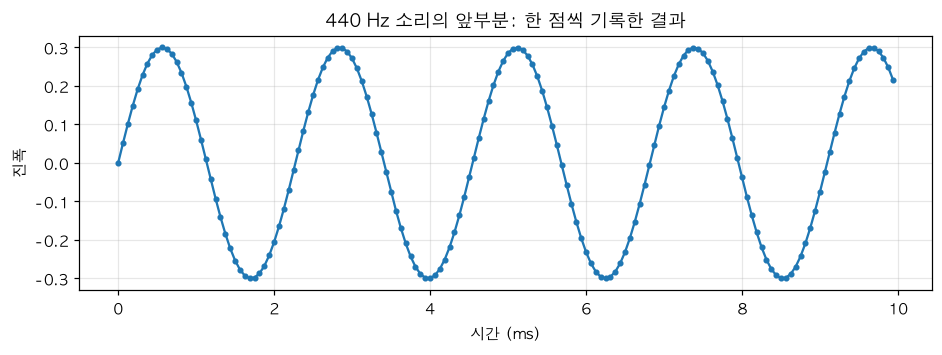

In [ ]:
tone = make_tone(frequency=440, duration=1.0, amplitude=0.3)
time = np.arange(len(tone)) / SR        # 0, 1, 2, … 번째 점이 몇 초인가
print("샘플 수:", len(tone), "/ 길이:", len(tone) / SR, "초")
print("앞 5개 시각(초):", time[:5])

plt.figure()
plt.plot(time[:160] * 1000, tone[:160], ".-")  # 앞 10ms 부근을 확대
plt.xlabel("시간 (ms)")                # 1초 = 1000ms
plt.ylabel("진폭")
plt.title("440 Hz 소리의 앞부분: 한 점씩 기록한 결과")
plt.grid(alpha=0.3)
plt.show()
display(Audio(tone, rate=SR, normalize=False))

샘플 수: 32000 / 길이: 2.0 초
앞 5개 시각(초): [0.000e+00 6.250e-05 1.250e-04 1.875e-04 2.500e-04]


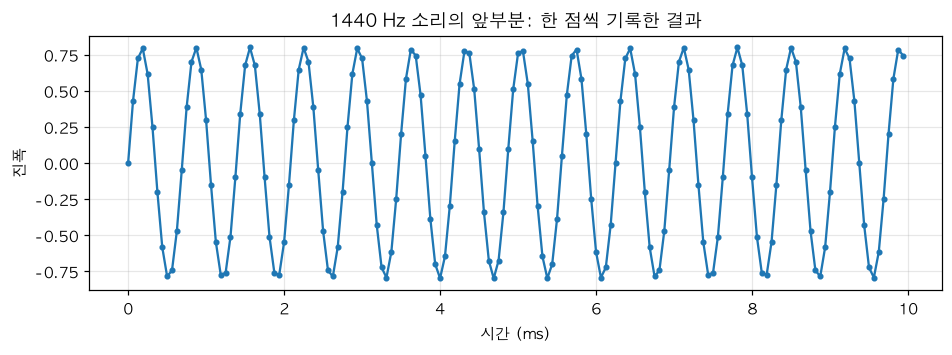

In [ ]:
tone = make_tone(frequency=1440, duration=2.0, amplitude=0.8) # frequence 더 큰 수 = 배열을 늘림, 같은 시간 안에 진동이 더 많아짐 -> 나의 질문 = amplitude는 뭐였지? 진폭, 소리 크기?
time = np.arange(len(tone)) / SR        # 0, 1, 2, … 번째 점이 몇 초인가
print("샘플 수:", len(tone), "/ 길이:", len(tone) / SR, "초")
print("앞 5개 시각(초):", time[:5])

plt.figure()
plt.plot(time[:160] * 1000, tone[:160], ".-")  # 앞 10ms 부근을 확대
plt.xlabel("시간 (ms)")                # 1초 = 1000ms
plt.ylabel("진폭")
plt.title("1440 Hz 소리의 앞부분: 한 점씩 기록한 결과")
plt.grid(alpha=0.3)
plt.show()
display(Audio(tone, rate=SR, normalize=False))

## 직접 해보기 B_15분

In [ ]:
# 나의 시도
answer_a = make_tone(frequency=16000, duration=0.5, amplitude=0.3) # 16000 Hz로 0.5초 녹음한 음성의 샘플 수
answer_b = make_tone(frequency=16000, duration=1.5, amplitude=0.3) # 16000 Hz로 1.5초 녹음한 음성의 샘플 수
answer_c = 24000  # 8000 Hz로 기록한 24000개 샘플의 길이(초)

assert answer_a is not None, "답을 적은 뒤 실행하세요."
assert answer_a == 16000 * 0.5, "a) SR × 초로 다시 계산해 보세요."
assert answer_b == 16000 * 1.5, "b) SR × 초로 다시 계산해 보세요."
assert answer_c == 24000 / 8000, "c) 샘플 수 ÷ SR로 다시 계산해 보세요."
print("모두 맞았습니다.")

ValueError: 주파수는 0보다 크고 SR의 절반보다 작게 설정하세요.

In [ ]:
# 강사님 답변
SR_a = 16000
answer_a = int(SR_a * 0.5)    # a) SR × 초 = 16000 × 0.5 = 8000개
answer_b = int(SR_a * 1.5)    # b) SR × 초 = 16000 × 1.5 = 24000개
answer_c = 24000 / 8000       # c) 샘플 수 ÷ SR = 24000 ÷ 8000 = 3.0초

print("a) 16000 Hz, 0.5초 →", answer_a, "개")
print("b) 16000 Hz, 1.5초 →", answer_b, "개")
print("c) 8000 Hz, 24000개 →", answer_c, "초")

assert answer_a is not None, "답을 적은 뒤 실행하세요."
assert answer_a == 16000 * 0.5, "a) SR × 초로 다시 계산해 보세요."
assert answer_b == 16000 * 1.5, "b) SR × 초로 다시 계산해 보세요."
assert answer_c == 24000 / 8000, "c) 샘플 수 ÷ SR로 다시 계산해 보세요."
print("모두 맞았습니다.")

a) 16000 Hz, 0.5초 → 8000 개
b) 16000 Hz, 1.5초 → 24000 개
c) 8000 Hz, 24000개 → 3.0 초
모두 맞았습니다.


## 도~솔 만들기

In [ ]:
# 나의 시도
# SR = 16000
notes = [262, 294, 330, 349, 392]   # 도 레 미 파 솔 각각에 해당하는 주파수
note_duration = 0.4                 # 한 음의 길이(초)
gap_duration = 0.1                  # 음 뒤의 쉼(초)

# 1) 실행 전에 직접 계산해서 적습니다.
answer_note_samples = int(SR * 0.4)    # 한 음(0.4초)의 샘플 수
answer_gap_samples = int(SR * 0.1)     # 쉼(0.1초)의 샘플 수
answer_total_samples = int(SR * answer_note_samples)    # 전체 멜로디의 샘플 수
answer_total_seconds = len(notes) * (note_duration + gap_duration)   # 전체 멜로디의 길이(초)

# 2) 멜로디 만들기
gap = np.zeros(int(SR * gap_duration))
parts = []
for f in notes:
    parts.append(make_tone(frequency=f, duration=note_duration, amplitude=0.3))
    parts.append(gap)
melody = np.concatenate(parts) # 쭉 이어줌

display(Audio(melody, rate=SR, normalize=False)) # 원음 그대로 사용, 스피커에 듣기 좋은 소리로 바꾸지 않음

assert answer_note_samples is not None, "답을 적은 뒤 실행하세요."
assert answer_note_samples == int(SR * note_duration), "한 음: SR × 초"
assert answer_gap_samples == len(gap), "쉼: SR × 초"
assert answer_total_samples == len(melody), "(한 음 + 쉼) × 음의 개수"
assert np.isclose(answer_total_seconds, len(melody) / SR), "전체 샘플 수 ÷ SR"
print("모두 맞았습니다.")

AssertionError: (한 음 + 쉼) × 음의 개수

In [29]:
# 정답 코드 — 이 셀만 실행해도 됩니다.
notes = [262, 294, 330, 349, 392]   # 도 레 미 파 솔
note_duration = 0.4
gap_duration = 0.1

gap = np.zeros(int(SR * gap_duration))
parts = []
for f in notes:
    parts.append(make_tone(frequency=f, duration=note_duration, amplitude=0.3))
    parts.append(gap)
melody = np.concatenate(parts)

answer_note_samples = int(SR * note_duration)       # 16000 × 0.4 = 6400
answer_gap_samples = int(SR * gap_duration)          # 16000 × 0.1 = 1600
answer_total_samples = (answer_note_samples + answer_gap_samples) * len(notes)  # 8000 × 5 = 40000
answer_total_seconds = answer_total_samples / SR     # 40000 ÷ 16000 = 2.5

print("한 음:", answer_note_samples, "개 / 쉼:", answer_gap_samples, "개")
print("전체:", answer_total_samples, "개 /", answer_total_seconds, "초")

# 더 해보기: 음별 주기와 한 주기의 샘플 수
# [주기(period, T)란] 파형이 "한 번 오르내리는 데 걸리는 시간". 주파수(f)의 역수라서 T = 1/f. (자세한 설명은 바로 아래 markdown 셀)
#  - 주파수 262 Hz = 1초에 262번 진동  ->  한 번 진동에 걸리는 시간 = 1/262 초 ≈ 0.00382초 = 3.82 ms
#  - 주파수가 높을수록(높은 음) 한 번 진동이 짧아서 주기도 짧다.

# zip(이름들, 주파수들) : "도"-262, "레"-294, ... 처럼 이름과 주파수를 짝지어 한 쌍씩 꺼낸다.
#  (notes = [262, 294, 330, 349, 392] 와 순서가 같아서 짝이 맞음. 반복마다 name = 음 이름, f = 그 음의 주파수)
for name, f in zip(["도", "레", "미", "파", "솔"], notes):
    # 1 / f * 1000 : 주기 T(초) = 1/f 를 밀리초(ms)로 바꾸려고 1000을 곱함 (1초 = 1000ms). 예) 1/262 * 1000 = 3.82 ms
    #   :.2f -> 소수점 둘째 자리까지 표시 (f-string 서식).  :.1f -> 소수점 첫째 자리까지
    # SR / f       : "한 주기 동안 기록되는 샘플 수" = (1초에 기록하는 샘플 수) ÷ (1초에 진동하는 횟수)
    #   예) 16000 / 262 ≈ 61.1  -> 도의 한 번 진동을 약 61개의 점으로 기록한다. (소수인 이유: 주기가 샘플 간격으로 딱 나누어떨어지지 않아서)
    print(f"{name} {f} Hz | 주기 {1 / f * 1000:.2f} ms | 한 주기 샘플 {SR / f:.1f}개")

assert answer_total_samples == len(melody)
display(Audio(melody, rate=SR, normalize=False))

한 음: 6400 개 / 쉼: 1600 개
전체: 40000 개 / 2.5 초
도 262 Hz | 주기 3.82 ms | 한 주기 샘플 61.1개
레 294 Hz | 주기 3.40 ms | 한 주기 샘플 54.4개
미 330 Hz | 주기 3.03 ms | 한 주기 샘플 48.5개
파 349 Hz | 주기 2.87 ms | 한 주기 샘플 45.8개
솔 392 Hz | 주기 2.55 ms | 한 주기 샘플 40.8개


### Q. 주기가 뭐야?

**한 줄 답: 주기(T)는 파형이 "한 번 오르내리는 데 걸리는 시간"이고, 주파수(f)의 역수입니다. `T = 1/f`**

#### 1. 쉬운 비유
- 그네를 **한 번 왕복하는 데 걸리는 시간** = 주기, **1초에 몇 번 왕복하는가** = 주파수.
- 시계 초침이 한 바퀴 도는 시간은 60초(주기), 1초에 `1/60`바퀴(주파수).
- 그래서 둘은 같은 이야기를 반대로 말한 것입니다. **자주 반복할수록(주파수 ↑) 한 번에 걸리는 시간(주기)은 짧아집니다.**

#### 2. 식과 단위
```text
T = 1 / f          f = 1 / T
주기 T : 초(s) 또는 밀리초(ms)      주파수 f : Hz (= 1/초, 1초에 몇 번)
1초 = 1000 ms
```
- 예: 1 Hz → 주기 1초 / 440 Hz → 약 2.273 ms / 1000 Hz → 1 ms (직접 계산한 값)

#### 3. 이 노트북의 도~솔로 확인하기
정답 코드의 마지막 `for`문이 출력하는 값입니다. (`SR = 16000`, 음 길이 0.4초, 직접 다시 계산해 확인)

| 음 | 주파수 f | 주기 T = 1/f | 한 주기의 샘플 수 (SR ÷ f) | 0.4초 동안 반복 횟수 (f × 0.4) |
|---|---|---|---|---|
| 도 | 262 Hz | 3.82 ms | 61.1개 | 약 104.8번 |
| 레 | 294 Hz | 3.40 ms | 54.4개 | 약 117.6번 |
| 미 | 330 Hz | 3.03 ms | 48.5개 | 132.0번 |
| 파 | 349 Hz | 2.87 ms | 45.8개 | 약 139.6번 |
| 솔 | 392 Hz | 2.55 ms | 40.8개 | 약 156.8번 |

- **높은 음일수록 주기가 짧습니다.** 도(3.82 ms) → 솔(2.55 ms)
- 한 주기를 기록하는 샘플 수도 줄어듭니다. 도는 약 61개, 솔은 약 41개. (앞서 정리한 "높은 음일수록 같은 SR에서 점이 적다"와 같은 이야기)
- **샘플 수가 소수인 이유**: 한 주기(예: 3.82 ms)가 샘플 간격 `1/SR = 0.0625 ms`로 딱 나누어떨어지지 않아서 "61.1개"처럼 나옵니다. (소리를 만들 때 문제는 없고, 샘플이 주기의 어느 지점에 찍히는지만 매번 조금씩 달라집니다.)

#### 4. 앞에서 본 사인 공식과 연결
`y = A · sin(2π · f · t)`에서 시간 `t`가 **T만큼 늘면** `2π·f·t`가 정확히 `2π`(한 바퀴)만큼 늘어나서 **같은 값으로 돌아옵니다.**
```text
y(t) = y(t + T)      ← 이 성질이 "주기적이다"의 뜻
```
440 Hz에서 `t`와 `t + 1/440`일 때 값을 비교했더니 최대 차이가 `4e-13`(컴퓨터 계산 오차 범위)이었습니다.
위의 "점 5개/9개/33개로 기록" 그래프에서 가로축 `position`이 0~1인 구간이 바로 **한 주기**입니다.

#### 5. 헷갈리기 쉬운 것
| 비교 | 구분 |
|---|---|
| 주기 vs 주파수 | 서로 역수. 주기는 "한 번에 걸리는 시간", 주파수는 "1초에 몇 번" |
| **주기 vs 샘플 간격** | 둘 다 시간이지만 **다른 것**입니다. 주기는 소리 파형의 한 번 진동(음마다 다름), 샘플 간격은 컴퓨터가 값을 기록하는 간격 `1/SR`(여기서는 0.0625 ms로 모든 음에 같음) |
| 주기 vs 파장 | 파장은 소리가 공간에서 한 번 진동하는 **길이**(m)이고 주기는 **시간**입니다. 소리의 파장은 `속도 ÷ 주파수`로 구하는 것이 일반적입니다. (일반 지식이며 이 노트북 범위 밖) |

(표와 440 Hz 확인값은 코드와 같은 식 `1000/f`, `SR/f`, `f*0.4`로 직접 계산했습니다. 비유와 파장 설명은 일반 지식입니다.)


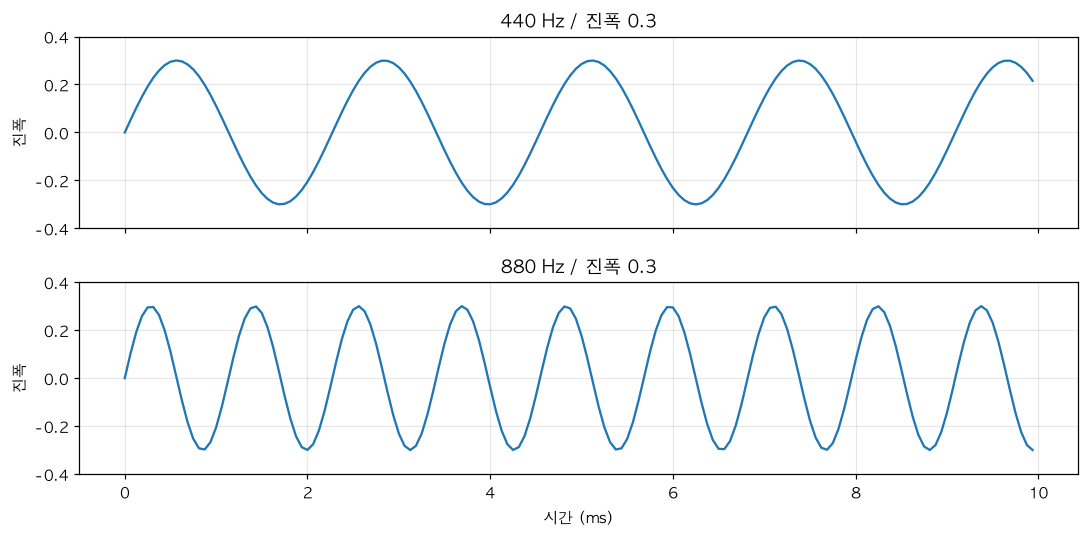

In [30]:
# 440Hz 사인파 생성
# 0.5초 동안 재생되며 진폭은 0.3
low = make_tone(frequency=440, duration=0.5, amplitude=0.3)

# 880Hz 사인파 생성
# 440Hz보다 주파수가 2배 높으므로 더 높은 음으로 들림
high = make_tone(frequency=880, duration=0.5, amplitude=0.3)

# 그래프에 표시할 처음 160개 샘플의 시간축 생성
# np.arange(160) : 0 ~ 159까지의 샘플 번호
# / SR           : 샘플 번호를 초(sec) 단위 시간으로 변환
# * 1000         : 초를 밀리초(ms)로 변환
short_time = np.arange(160) / SR * 1000


# 2행 1열의 그래프 생성
# sharex=True  : 두 그래프의 시간축을 동일하게 사용
# sharey=True  : 두 그래프의 진폭축을 동일하게 사용
fig, axes = plt.subplots(
    2, 1,
    figsize=(10, 5),
    sharex=True,
    sharey=True
)

# 440Hz 파형의 처음 160개 샘플을 그림
axes[0].plot(short_time, low[:160])
axes[0].set_title("440 Hz / 진폭 0.3")

# 880Hz 파형의 처음 160개 샘플을 그림
axes[1].plot(short_time, high[:160])
axes[1].set_title("880 Hz / 진폭 0.3")


# 두 그래프에 공통 설정 적용
for ax in axes:
    ax.set_ylabel("진폭")

    # 두 그래프의 세로축 범위를 동일하게 설정
    ax.set_ylim(-0.4, 0.4)

    # 파형을 쉽게 비교할 수 있도록 격자 표시
    ax.grid(alpha=0.3)


# 아래쪽 그래프의 가로축 이름 설정
axes[1].set_xlabel("시간 (ms)")

# 그래프 요소가 겹치지 않도록 자동 배치
plt.tight_layout()

# 그래프 출력
plt.show()

In [31]:
# 440Hz 사인파 재생
print("440 Hz")

# low 배열에 저장된 음성 데이터를 SR 샘플링 주파수로 재생
# normalize=False : 진폭값을 자동으로 키우지 않고 원래 크기 그대로 재생
display(Audio(low, rate=SR, normalize=False))


# 880Hz 사인파 재생
print("880 Hz")

# high 배열에 저장된 음성 데이터를 SR 샘플링 주파수로 재생
# 440Hz보다 주파수가 2배 높으므로 더 높은 음으로 들림
display(Audio(high, rate=SR, normalize=False))

440 Hz


880 Hz


주파수가 2배가 되면, 주기는 __ + 샘플 수는 __ 변한다

**답: 주기는 절반(1/2)으로 줄고, 한 주기의 샘플 수도 절반으로 줄어요.**

주기와 한 주기의 샘플 수는 둘 다 주파수 `f`가 분모에 있는 식이라, `f`가 2배가 되면 둘 다 1/2이 돼요.
```text
T = 1 / f           (주기)
한 주기의 샘플 수 = SR ÷ f
```

도(262 Hz)의 주파수를 2배로 키운 값(524 Hz)으로 비교하면 이래요. SR은 16000이에요.

| | 262 Hz | 524 Hz (2배) | 변화 |
|---|---|---|---|
| 주기 T = 1/f | 3.82 ms | 1.91 ms | 절반 |
| 한 주기의 샘플 수 = SR÷f | 61.1개 | 30.5개 | 절반 |

한 옥타브 올라가면 주파수가 2배가 된다고 한 말과 이어져요.

**주의할 점**
- 빈칸의 "샘플 수"가 **한 주기를 기록하는 샘플 수**라면 위 답이 맞아요. 이 노트북의 "한 주기 샘플" 줄과 같은 뜻이에요.
- 만약 **소리 전체의 샘플 수**(`SR × 초`)를 묻는 거라면, 주파수가 달라져도 SR과 길이가 같으면 **변하지 않아요**(예: 16000 × 0.4 = 6400개). 이 두 가지를 헷갈리기 쉬워요.
- 문제에 "한 주기"라는 말이 있었는지 확인해 보세요. 없고 그냥 "샘플 수"라면 강사님께 어느 쪽인지 물어보시는 게 좋아요.

각 값을 직접 계산해서 확인했어요(1000÷262≈3.82, 1000÷524≈1.91, 16000÷262≈61.1, 16000÷524≈30.5).


In [32]:
for frequency in [220, 440, 880, 1760]:
    period_ms = 1 / frequency * 1000          # 한 번 오르내리는 시간(ms)
    repeats_10ms = frequency * 0.01           # 10ms 동안 반복 횟수
    samples_per_period = SR / frequency       # 한 주기 동안 기록하는 샘플 수
    print(f"{frequency:>5} Hz | 주기 {period_ms:5.2f} ms | 10ms 안 {repeats_10ms:5.1f}번 | 한 주기 샘플 {samples_per_period:5.1f}개")

  220 Hz | 주기  4.55 ms | 10ms 안   2.2번 | 한 주기 샘플  72.7개
  440 Hz | 주기  2.27 ms | 10ms 안   4.4번 | 한 주기 샘플  36.4개
  880 Hz | 주기  1.14 ms | 10ms 안   8.8번 | 한 주기 샘플  18.2개
 1760 Hz | 주기  0.57 ms | 10ms 안  17.6번 | 한 주기 샘플   9.1개


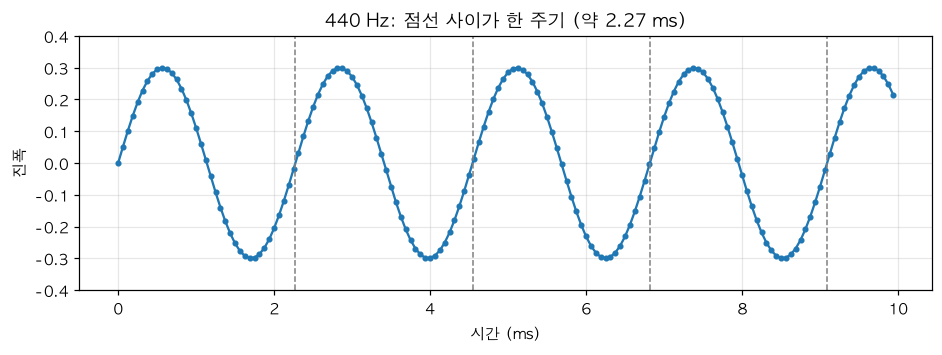

In [34]:
# 440 Hz 소리의 주기(한 번 오르내리는 시간)를 ms 단위로 계산: T = 1/f = 1/440 초 ≈ 0.00227초 = 약 2.273 ms
period_ms = 1 / 440 * 1000

plt.figure()
plt.plot(short_time, low[:160], ".-")   # 가로축 = 시간(ms) (처음 160개 샘플 = 0 ~ 약 9.94 ms), 세로축 = 진폭

# [k * period_ms 가 무슨 뜻인가]
#  period_ms = 한 주기의 길이(ms)  ->  k * period_ms = "한 주기 길이를 k번 더한 시각" = "k번째 주기가 끝나는 시각(ms)"
#   k=1 -> 1 × 2.273 =  2.273 ms   (첫 번째 주기가 끝나는 시점)
#   k=2 -> 2 × 2.273 =  4.545 ms   (두 번째 주기가 끝나는 시점)
#   k=3 -> 3 × 2.273 =  6.818 ms
#   k=4 -> 4 × 2.273 =  9.091 ms
#  가로축이 시간(ms)이라 이 값이 곧 "점선을 그을 가로축 위치(x좌표)"가 된다.
#  (k=0, 즉 0 ms 위치는 그래프의 왼쪽 끝이라 따로 점선을 긋지 않았다. 0 ~ 첫 점선 사이도 한 주기이다.)
#
# [range(1, 5)] k를 1, 2, 3, 4로 돌린다(5는 포함하지 않음) -> 점선 4개.
#  k=5이면 5 × 2.273 = 11.36 ms 인데, 그래프가 약 9.94 ms 까지만 보여 주므로 범위 밖이라 그릴 필요가 없다.
for k in range(1, 5):
    # plt.axvline(x, ...) : 가로축 위치 x 에 "세로 방향 선" 하나를 긋는다. (vertical line. 가로선은 axhline)
    #   - k * period_ms     : 점선을 그을 위치 (x좌표, 단위 ms)
    #   - color="gray"      : 회색
    #   - linestyle="--"    : 점선 (실선은 "-")
    #   - linewidth=1       : 선 굵기
    # 점선 사이 간격이 정확히 주기(2.273 ms)이고, 점선과 점선 사이의 파형이 "한 번 오르내림"이다.
    # 점선은 샘플 사이에 걸칠 수 있다. 한 주기가 36.36개 샘플(16000 ÷ 440)이라 정수가 아니기 때문이다.
    plt.axvline(k * period_ms, color="gray", linestyle="--", linewidth=1)  # 한 주기마다 점선
plt.xlabel("시간 (ms)")
plt.ylabel("진폭")
plt.title(f"440 Hz: 점선 사이가 한 주기 (약 {period_ms:.2f} ms)")
plt.ylim(-0.4, 0.4)
plt.grid(alpha=0.3)
plt.show()

## 실습 10 — 같은 소리를 서로 다른 SR로 만들기

**SR이 높아지면 소리의 주파수도 높아질까요?** 주파수·길이·진폭은 같게 두고, SR만 다르게 지정하여 두 소리를 만들어 확인합니다.

이번에는 기존 배열의 재생 속도를 바꾸는 것이 아니라, **각 SR에 맞는 배열을 `make_tone()`으로 각각 새로 만듭니다.**

| 조건 | 소리 A | 소리 B |
|---|---:|---:|
| 주파수 | 500Hz | 500Hz |
| 길이 | 1.2초 | 1.2초 |
| 진폭 | 0.2 | 0.2 |
| SR | 8000Hz | 16000Hz |

**작성할 내용**

1. 두 소리의 전체 샘플 수를 먼저 예상하세요.
2. `make_tone()`의 `sr` 인수를 각각 지정하여 배열 A와 B를 만드세요.
3. 각 배열의 샘플 수와 길이를 출력하세요. 길이는 **각 배열에 사용한 SR**로 계산합니다.
4. 두 소리의 주기(ms)와 한 주기에 해당하는 샘플 수를 계산하세요.
5. 각각 **처음 10ms에 해당하는 샘플**을 선택하여 위아래 두 그래프로 그리세요. 점이 보이도록 `".-"`를 사용하고, 가로축과 세로축 범위는 동일하게 맞추세요.
6. A는 `rate=8000`, B는 `rate=16000`으로 재생하세요. 두 경우 모두 `normalize=False`를 사용합니다.

**계산 힌트**

- 전체 샘플 수: `SR × 길이(초)`
- 주기(ms): `1000 ÷ 주파수`
- 한 주기에 해당하는 샘플 수: `SR ÷ 주파수`
- 처음 10ms에 해당하는 샘플 수: `int(SR × 0.01)`
- 각 샘플의 시각(ms): `샘플 번호 ÷ SR × 1000`

**결과를 기록하세요.**

| 확인 항목 | 소리 A | 소리 B |
|---|---|---|
| 전체 샘플 수 | | |
| 계산한 길이 | | |
| 주기(ms) | | |
| 한 주기에 해당하는 샘플 수 | | |
| 처음 10ms에 해당하는 샘플 수 | | |

마지막으로 다음 질문에 자신의 말로 답하세요.

> 두 소리의 샘플 수는 다른데, 왜 재생 시간과 음의 높이는 같을까요? 그래프에서 반복 간격과 점의 촘촘함을 구분하여 설명하세요.

**완료 기준:** SR을 높였을 때 늘어나는 것이 무엇인지, 주파수를 높였을 때 달라지는 것과 구분하여 설명할 수 있어야 합니다.

---

#### cf. 스스로 풀기 위한 공식 모음 (정답은 적지 않았습니다, by claude code)

**기호 약속**: `SR` = 샘플링 레이트(샘플/초), `f` = 주파수(Hz = 진동/초), `t` = 시간(초), `T` = 주기(초), `N` = 샘플 수(개)

**1. 기본 공식 (이 실습의 모든 계산이 여기서 나옵니다)**

| 구하는 것 | 공식 | 단위 확인 | 코드로 쓰면 |
|---|---|---|---|
| 전체 샘플 수 | `N = SR × t` | (샘플/초) × 초 = 샘플 | `sr * duration` |
| 길이(초) | `t = N ÷ SR` | 샘플 ÷ (샘플/초) = 초 | `len(array) / sr` |
| 주기 | `T = 1 ÷ f` (초) = `1000 ÷ f` (ms) | 1 ÷ (진동/초) = 초/진동 | `1 / frequency * 1000` |
| 한 주기에 해당하는 샘플 수 | `SR ÷ f` | (샘플/초) ÷ (진동/초) = 샘플/진동 | `sr / frequency` |
| 처음 10 ms에 해당하는 샘플 수 | `SR × 0.01` (10 ms = 0.01초) | (샘플/초) × 초 = 샘플 | `int(sr * 0.01)` |
| 각 샘플의 시각(ms) | `번호 ÷ SR × 1000` | 번호 ÷ (샘플/초) = 초 → ×1000 = ms | `np.arange(개수) / sr * 1000` |
| 일정 시간 동안 반복 횟수 | `f × t` | (진동/초) × 초 = 진동 | `frequency * 0.01` |

**2. 단위를 먼저 쓰고 계산하는 요령**
식을 떠올리기 어려우면 **구하려는 단위를 먼저 적고**, 가진 값들의 단위를 곱하거나 나누어 그 단위가 되게 맞추면 됩니다.
```
구하는 것: "개"(샘플 수)  /  가진 것: SR = 샘플/초, 시간 = 초   →   (샘플/초) × 초 = 샘플
```

**3. 이 실습에서 같이 알아 둘 것**
- `make_tone(frequency, duration, amplitude, sr)`의 **`sr`** 인수에 SR을 지정합니다. (위쪽 `make_tone` 셀에서 인수 이름과 기본값을 확인하세요.) 함수 안에서 `time = np.arange(샘플 수) / sr`로 시간을 만들고 `sin(2π·f·time)`을 계산합니다.
- `make_tone`은 **`0 < 주파수 < SR ÷ 2`** 이어야 만들어집니다 (그 이상이면 `ValueError`). 이 실습의 조건(500 Hz)이 두 SR에서 이 범위 안에 있는지 직접 확인해 보세요.
- 시각이 **ms**이고 `SR`이 **샘플/초**라서 `÷ SR` 다음에 **`× 1000`** 을 해야 ms가 됩니다. (앞쪽 "실습6. 시간 축 만들기"의 `time[:160] * 1000` 참고)
- 두 그래프를 **같은 10 ms 구간**으로 그리려면 가로축 범위를 같게 맞추는 옵션이 필요합니다. 앞의 440 Hz와 880 Hz 비교 그래프 셀에서 `plt.subplots(2, 1, sharex=True, sharey=True)`와 `ylim`을 쓴 방법을 참고하세요.
- 재생은 앞의 `display(Audio(배열, rate=SR값, normalize=False))` 형태를 그대로 쓰되, **A는 `rate=8000`, B는 `rate=16000`** 입니다.

**4. 마지막 질문을 풀 때 스스로 물어볼 것** (답은 직접 정리해 보세요)
1. SR이 2배가 되면 **1초 동안 기록하는 점의 수**는 어떻게 되나? (그래프에서는 점의 **촘촘함**)
2. SR이 2배가 되어도 **주파수와 주기**(반복 간격, ms)는 바뀌나? (그래프에서는 **파형이 반복되는 간격**)
3. 처음 10 ms 안에 **파형이 반복되는 횟수**는 두 소리가 같은가? 그 안에 찍힌 **점의 수**는 같은가?
4. 주파수를 **2배**로 올렸을 때(앞의 연습 문제)와 **SR을 2배**로 올렸을 때를 비교하면, 각각 무엇이 달라지고 무엇이 그대로인가?

**5. 결과가 맞는지 스스로 확인하는 방법**
```python
assert len(배열A) == 전체_샘플_수_예상A      # 내가 예상한 값과 make_tone이 만든 배열 길이가 같은가
assert np.isclose(len(배열A) / 8000, 길이A)   # 샘플 수 ÷ SR 이 1.2초가 나오는가
```
예상값을 **실행 전에** 먼저 적어 두고, 나중에 `len(배열)`과 비교하면 계산 습관을 점검할 수 있습니다.


소리 A | SR 8000 | 샘플 수 9600 | 길이 1.2초 | 주기 2.0 ms | 한 주기 샘플 16개 | 처음 10ms 샘플 80개
소리 B | SR 16000 | 샘플 수 19200 | 길이 1.2초 | 주기 2.0 ms | 한 주기 샘플 32개 | 처음 10ms 샘플 160개


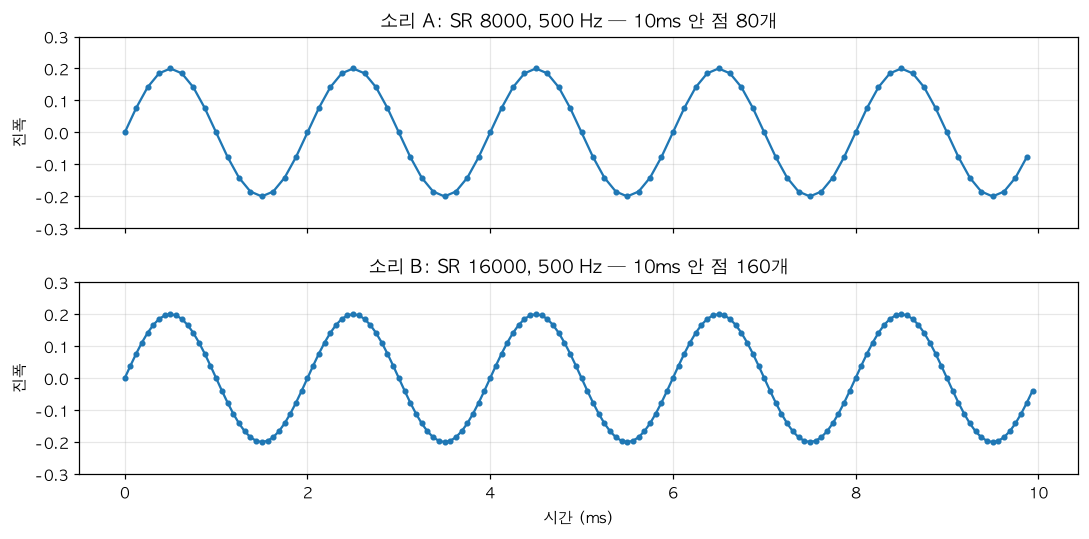

소리 A (rate=8000)


소리 B (rate=16000)


In [36]:
# 정답 코드
frequency = 500
duration = 1.2
amplitude = 0.2
sr_a = 8000
sr_b = 16000

tone_a = make_tone(frequency=frequency, duration=duration, amplitude=amplitude, sr=sr_a)
tone_b = make_tone(frequency=frequency, duration=duration, amplitude=amplitude, sr=sr_b)

for name, x, sr in [("소리 A", tone_a, sr_a), ("소리 B", tone_b, sr_b)]:
    print(f"{name} | SR {sr} | 샘플 수 {len(x)} | 길이 {len(x) / sr}초 "
          f"| 주기 {1000 / frequency} ms | 한 주기 샘플 {sr / frequency:.0f}개 | 처음 10ms 샘플 {int(sr * 0.01)}개")

# 처음 10ms 비교 그래프: 시간축은 각 배열의 SR로 만듭니다.
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True, sharey=True)
for ax, name, x, sr in [(axes[0], "소리 A", tone_a, sr_a), (axes[1], "소리 B", tone_b, sr_b)]:
    n = int(sr * 0.01)
    t_ms = np.arange(n) / sr * 1000
    ax.plot(t_ms, x[:n], ".-")
    ax.set_title(f"{name}: SR {sr}, 500 Hz — 10ms 안 점 {n}개")
    ax.set_ylabel("진폭")
    ax.set_ylim(-0.3, 0.3)
    ax.grid(alpha=0.3)
axes[1].set_xlabel("시간 (ms)")
plt.tight_layout()
plt.show()

print("소리 A (rate=8000)")
display(Audio(tone_a, rate=sr_a, normalize=False))
print("소리 B (rate=16000)")
display(Audio(tone_b, rate=sr_b, normalize=False))

## 실습11.

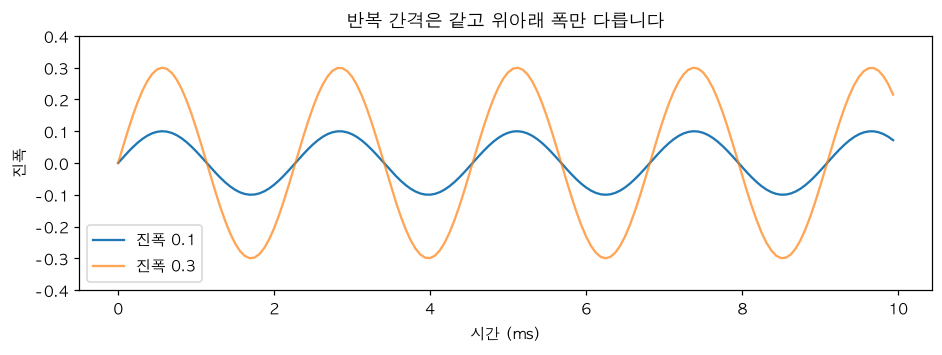

진폭 0.1


진폭 0.3


In [37]:
# 같은 440Hz 주파수의 사인파를 만들되 진폭만 다르게 설정
# quiet  : 진폭 0.1 -> 작은 소리
# louder : 진폭 0.3 -> 더 큰 소리
quiet = make_tone(frequency=440, duration=0.5, amplitude=0.1)
louder = make_tone(frequency=440, duration=0.5, amplitude=0.3)


# 두 파형을 하나의 그래프에 겹쳐서 비교
plt.figure()

# 진폭 0.1 파형
plt.plot(short_time, quiet[:160], label="진폭 0.1")

# 진폭 0.3 파형
# alpha=0.7 : 그래프 선을 약간 투명하게 표시
plt.plot(short_time, louder[:160], label="진폭 0.3", alpha=0.7)

# 그래프의 가로축과 세로축 이름 설정
plt.xlabel("시간 (ms)")
plt.ylabel("진폭")

# 두 파형은 주파수가 같기 때문에 반복 간격은 같고,
# 진폭만 다르기 때문에 위아래 크기만 다르게 보임
plt.title("반복 간격은 같고 위아래 폭만 다릅니다")

# 두 파형의 크기를 쉽게 비교할 수 있도록
# 세로축 범위를 -0.4 ~ 0.4로 고정
plt.ylim(-0.4, 0.4)

# 각 선이 어떤 진폭인지 범례 표시
plt.legend()

# 그래프 출력
plt.show()


# 진폭 0.1인 소리 재생
print("진폭 0.1")
display(Audio(quiet, rate=SR, normalize=False))

# 진폭 0.3인 소리 재생
# 주파수는 같으므로 음의 높이는 같고,
# 진폭이 더 크기 때문에 더 크게 들림
print("진폭 0.3")
display(Audio(louder, rate=SR, normalize=False))

## 2026.10.20 (23일차) 나의 학습 체감 분석 — "왜 이번엔 빠르고 어렵게 느껴질까?"와 앞으로의 가이드

> 이 글의 근거는 **지금까지 이 저장소에서 한 질문, 노트북 날짜, 노트북에 있는 강사님 코드·설명**입니다.
> 수업 현장에서 실제로 강사님이 얼마나 빨리 진행하셨는지, 본인의 컨디션과 선수 지식은 제가 볼 수 없어서 **아래 원인은 확인된 사실이 아니라 근거 있는 추정**입니다.

---

### 1. 먼저, 결론
**"내가 갑자기 이해를 못하게 됐다"기보다 "이번 주제가 이전과 다른 종류의 지식을 요구하고, 짧은 시간에 새 용어가 한꺼번에 쏟아졌다"는 쪽이 더 설득력 있습니다.**
질문 내용을 보면 이해력의 문제가 아니라 **선수 용어(기초 어휘)를 아직 갖추지 못한 상태에서 바로 응용으로 들어간 것**으로 보입니다. 이건 보통 누구에게나 일어나는 일이고, 어휘를 채우면 체감이 많이 내려가는 종류의 어려움입니다.

---

### 2. 근거 1 — 주제 전환이 매우 빨랐다 (노트북 날짜로 확인)

| 날짜 | 주제 (저장소 폴더) |
|---|---|
| 10/13~14 | Seq2Seq (`010_seq2seq`) |
| 10/14~15 | Attention (`011_attention_mechanism`) |
| 10/15 | Transformer (`012_transformer`) |
| 10/16 | OpenAI API (`013_openai_api`) |
| 10/19 | LangChain, LangGraph, RAG (`014`~`016`) |
| 10/20 | **소리/음성 (`017_sound`)** |

수업 6일 동안 **다른 주제가 6번 바뀌었습니다.** 주제가 바뀔 때마다 새 용어, 새 라이브러리, 새 사고방식을 다시 세팅해야 해서 피로가 누적되기 쉽습니다. 오늘은 그 마지막 전환이었고, 그 전환이 **"모델/코드 중심" → "신호/물리/수학 중심"**이라는 **성격이 크게 다른 이동**이었습니다.

### 3. 근거 2 — 앞의 주제와 요구하는 지식의 종류가 다르다
| | 지금까지 (Keras, NLP, LangChain 등) | 오늘 (소리) |
|---|---|---|
| 핵심 | 데이터 → 모델 → 결과 (프로그래밍·API 중심) | 소리 = 시간에 따른 **물리량** → 숫자 (신호·수학·물리 중심) |
| 배경지식 | Python, 배열 모양(shape), API 사용법 | 사인 함수, 라디안(2π), 주파수·주기·진폭, 단위(Hz, kHz, ms), 샘플링 |
| 코드와 개념의 거리 | 가깝다 (코드를 읽으면 개념이 보임) | **멀다** (사인 식·단위 계산 없이는 코드가 무엇을 뜻하는지 안 보임) |

오늘 한 질문들이 이 차이를 그대로 보여 줍니다.
- "**진폭이 뭐야?**", "**주기가 뭐야?**", "**낮은 음이 뭐야? (음자리표, 건반)**" → 코드가 아니라 **용어와 배경지식**을 묻는 질문입니다.
- 앞의 주제 때의 질문("RetrievalQA는 어느 부분이 검색이고 생성인가", "`app`의 type은?")은 **코드와 개념을 연결**하는 질문이었습니다.
- 즉 지금 막힌 곳은 "이 코드가 어떻게 동작하나"가 아니라 "**이 말이 무슨 뜻인가**"입니다. 이 종류의 막힘은 정의를 한 번 정리하면 비교적 빨리 풀립니다.

### 4. 근거 3 — 새 용어와 코드가 같은 시간에 겹쳤다
오늘 노트북(20시~)에서 강사님이 쓰신 용어만 세어도 이만큼입니다. (제가 노트북을 읽고 센 것)

> **샘플, SR(샘플링 레이트), 진폭, 주파수, Hz/kHz, 사인파(sin), 라디안(2π), 시간 축(ms), 샘플 수↔길이 변환, 주기, Nyquist 주파수**(코드 주석에 등장)

여기에 **matplotlib 문법**(`subplots`, `zip`, `linspace`, `axhline`, `f-string 서식`, `plt.ylim` 등)과 numpy(`np.arange`, `np.concatenate`, `np.zeros`)까지 한 시간대에 같이 나왔습니다. 즉 **"개념 새로 배우기 + 그래프 문법 새로 배우기"를 동시에** 하고 있었습니다. 코드 줄 설명을 다시 요청하신 것도(`plt.subplots` 셀) 이 부담이 겹친 결과로 보입니다.

### 5. 근거 4 — 수업 설계 자체가 빠른 편으로 보인다
- 노트북에 **"직접 해보기 B_15분"**이 있고, 바로 아래에 **"정답 코드 — 이 셀만 실행해도 됩니다"**라고 되어 있습니다. 15분에 끝내기 어려운 사람이 있다는 걸 전제로 한 구성입니다.
- 질문하신 "주기", "단위 변환" 같은 개념이 **정의 없이 코드 안에서 먼저 쓰입니다.** (예: 도~솔 만들기의 `주기 {1 / f * 1000:.2f} ms`)
- 이건 제 판단이고, 강사님이 구두로 풀어 주셨을 가능성은 배제할 수 없습니다.

### 6. 이 체감이 "능력 문제"가 아니라고 보는 이유
- 질문의 질이 좋습니다. "**소리가 왜 사인인가(우연? 필연?)**", "**진폭이 악상 기호(forte, pianissimo)와 같은 개념인가**", "**주파수와 어떤 관계인가**"처럼 **개념끼리 연결해서** 이해하려는 질문입니다. 암기가 아니라 이해 중심입니다.
- 지금까지 어려운 개념(Seq2Seq, Attention, Transformer의 Positional Encoding, √d_k)도 **"왜?"를 끝까지 파고들어서** 정리해 왔습니다.
- 어려운 이유가 "용어 기반이 아직 없어서"라면, 기반을 채우는 데 **며칠이면 충분한 종류**입니다.

(참고: 이 판단은 대화 속 질문들에서 본 패턴이고, 학습 성과를 객관적으로 평가한 것은 아닙니다.)

---

### 7. 앞으로 수업을 따라가기 위한 가이드

#### (1) 이번 주 안에 "소리 용어 한 장 요약"을 만든다 (30분)
이 노트북의 설명 셀(진폭/주파수/주기/사인)을 그대로 한 장에 줄여서 쓰면 됩니다. 꼭 들어갈 식 5개:

```text
T = 1 / f                    (주기 = 1/주파수)
샘플 수 = SR × 시간(초)         (예: 16000 × 0.4 = 6400)
시간(초) = 샘플 수 ÷ SR
한 주기의 샘플 수 = SR ÷ f      (예: 16000 ÷ 262 ≈ 61.1)
y = A · sin(2π · f · t)         (A 진폭, f 주파수, t 시간)
```
용어 순서도 한 줄로 외워 두면 좋습니다: **소리 → (샘플링) → 숫자 배열 → 주파수/진폭 → 이후 FFT/스펙트로그램**.

#### (2) "단위를 붙여서" 계산하는 습관 (이미 노트북에 있는 방식)
`샘플 ÷ (샘플/초) = 초`처럼 **단위가 맞는지**를 보면 식을 외우지 않아도 됩니다. 막히면 단위부터 쓰세요.

#### (3) 질문을 "핵심"과 "보너스"로 나눈다
오늘 한 질문 중 진도에 **바로 필요한 것**과 **이해를 넓히는 것**을 구분하면 시간 압박이 줄어듭니다.

| 구분 | 예 | 다음 수업에 필요? |
|---|---|---|
| **핵심** | SR, 샘플 수, 길이(초) 변환, 주파수·진폭·주기의 뜻, 소리 = 숫자 배열 | **필요 (반드시)** |
| 보너스 | forte/pianissimo, 음자리표와 건반, 사인이 필연인 물리적 이유, 푸리에의 수학 | 호기심·이해 확장. **당장 시험·실습에 안 나와도 됨** |

보너스 질문은 이미 노트북에 답이 적혀 있으니 **복습으로 읽기만** 해도 충분합니다. 수업 중에는 핵심 질문만 잡는 것이 좋습니다.

#### (4) 수업 전·중·후 15분 루틴
| 시점 | 할 일 |
|---|---|
| **수업 전 (10분)** | 오늘 주제의 **새 용어 3개**만 먼저 검색해서 한 줄씩 적는다. 용어에 익숙해진 채로 들으면 코드가 훨씬 잘 보인다 |
| **수업 중** | 코드 한 줄이 이해 안 가면 **멈추지 말고 `?`만 표시**하고 일단 실행·결과 확인까지 따라간다. 이해 못한 줄은 쉬는 시간이나 수업 후에 모아서 묻는다 |
| **수업 후 (15분)** | 오늘 만든 함수(`make_tone`)의 **숫자를 바꿔 보고**(주파수, 진폭, 길이) 소리와 그래프가 어떻게 변하는지 확인한다. 이해는 직접 변경해 볼 때 가장 빠르게 붙는다 |

#### (5) 앞으로 나올 내용의 지도 (README 커리큘럼 기준, 일정은 바뀔 수 있음)
- **5주차 "음성이 모델 입력이 되는 과정"**: 파형·샘플링, WAV 전처리, **FFT·STFT, Spectrogram, Mel/Log-Mel** ← 오늘이 이 시작입니다. 앞으로 **가장 수학이 많이 나오는 구간**일 수 있어서, **수식 유도보다 "입력 모양이 어떻게 바뀌나"(shape)**를 먼저 잡으세요.
- **6주차 "STT/TTS 모델 이해와 실제 활용"**: Whisper, WER/CER, TTS 구조 — 이 부분은 이미 해본 **OpenAI API(Whisper, TTS)와 모델 개념(Transformer)**이 연결되어서 상대적으로 편할 수 있습니다.
- 남은 날은 10/21~11/12 사이 평일이 17일입니다. (프로젝트 2주가 마지막에 있어서 강의 일수는 이보다 적을 수 있고, 정확한 일정은 확인이 필요합니다.)

#### (6) 막혔을 때 쓸 수 있는 방법 (효율 순)
1. **15분 규칙**: 한 개념에 15분 써도 안 풀리면 질문으로 넘긴다.
2. **질문할 때 "어디까지 이해했는지"를 한 줄 덧붙인다** (예: "주기는 알겠는데 왜 1/f인지 모르겠어요").
3. 강사님께 **필요한 선수 지식 목록**과 **참고 자료**를 한 번 요청한다. (수학/물리 기초가 필요한 단원이라 이 요청은 자연스럽습니다.)
4. 동료 수강생과 **서로 설명해 보기** (설명할 수 있으면 이해한 것).
5. 이 노트북처럼 **궁금증을 셀로 남기는 습관**은 계속 유지하세요. 지금 가장 좋은 복습 자료가 이미 만들어지고 있습니다.

#### (7) 컨디션
수업이 19시~22시 50분이고 노트북 기록으로 보면 밤 늦게까지 공부하는 날이 많습니다. 새 주제가 어려울수록 **피로가 체감 난이도를 키웁니다.** 이해가 안 되는 날은 억지로 늘리기보다, 쉬고 다음 날 아침에 이 노트북의 설명 셀을 10분만 다시 읽는 편이 효과적일 수 있습니다. (일반적인 학습 조언이고, 개인 상황은 다를 수 있습니다.)

---

### 8. 정리 (한 장)
| 질문 | 답 |
|---|---|
| 왜 이번엔 어렵고 빠르게 느껴지나? | ① 주제가 6일 동안 6번 바뀌어서 피로 누적 ② 이번 주제가 **신호·수학·물리 용어**를 요구 ③ 용어와 그래프 문법이 **동시에** 나옴 ④ 수업 설계가 빠른 편으로 보임 (추정) |
| 이해력 문제인가? | 질문 패턴상 **아니라고 보는 쪽이 설득력 있음**. 선수 용어를 채우면 풀리는 종류 |
| 지금 해야 할 한 가지는? | **소리 용어 + 식 5개 한 장 요약** (T=1/f, 샘플 수=SR×초, SR÷f 등) |
| 앞으로의 핵심 전략은? | 수업 전 용어 3개 → 수업 중 `?` 표시만 → 수업 후 숫자 바꿔 실험 |


## 소리 다루기 Cheat Sheet (2장 세트)

오늘 헷갈렸던 개념(샘플 수, SR, 주파수, 주기, 길이, 진폭 등)을 **용어 + 공식 + 계산 예시 + 파형 + 수업 코드 + 주의**가 한 지면에 보이도록 정리한 포스터입니다.
실습 문제를 풀다가 막히면 **시트 ①**부터 보고, "왜?"가 궁금하면 **시트 ②**를 보세요.
(파일: `sound_cheatsheet_1_main.png`, `sound_cheatsheet_2_deep.png` / 만드는 코드: `make_sound_cheatsheet.py`)

- **시트 ① 한 장 요약**: 파형 그림에 용어를 직접 표시 + ①~⑫ 카드(정의, 공식, 예시, 수업 코드, ★주의) + "도 한 음을 녹음하는 하루" 스토리 recap
- **시트 ② 심화 Q&A**: 나이퀴스트(왜 SR÷2 미만인가), 한 주기 샘플 수 공식의 이유, n번째 샘플의 시각(타임라인), 처음 10 ms의 0.01, 사인파 공식, 옥타브, 반음 ×1.0595와 평균율
- 표기: 샘플 수 `N` · 샘플링 레이트 `SR` · 길이 `t` · 진폭 `A` · 주파수 `f` · 주기 `T`  /  ★ = 주의, † = 수업 자료에는 없던 보충 설명

![소리 다루기 cheat sheet ① 한 장 요약](sound_cheatsheet_1_main.png)

![소리 다루기 cheat sheet ② 심화 Q&A](sound_cheatsheet_2_deep.png)


## POP QUIZ + 답안

### 문제. 주파수와 샘플링 레이트(sampling rate, SR)의 차이점은?

**한 문장 답안**
> **주파수는 소리가 1초에 진동하는 횟수(음의 높낮이)이고, 샘플링 레이트는 컴퓨터가 그 소리를 1초에 읽어서 기록하는 샘플 수(기록의 촘촘함)이다. 둘 다 단위가 Hz지만 진동 횟수와 기록 횟수라서 서로 다르다.**

**비교표**

| | 주파수 (f) | 샘플링 레이트 (SR) |
|---|---|---|
| 무엇의 성질? | **소리 자체**의 성질 | **기록 방식**의 설정 |
| 뜻 | 1초에 진동하는 횟수 | 1초에 읽어 저장하는 샘플 수 |
| 단위 | Hz (= 진동/초) | Hz (= 샘플/초) |
| 바꾸면 | **음이 높아지거나 낮아짐** | **점이 촘촘해지거나 듬성해짐** (음 높이는 그대로) |
| 예 | 440 Hz (라) | 16000 Hz (이 수업 기준) |

- 둘 다 Hz라서 헷갈리지만 **진동 횟수 vs 기록 횟수**로 다른 것입니다.
- **SR을 올려도 소리가 높아지지 않습니다.** 같은 소리를 더 촘촘하게 기록할 뿐입니다. (소리를 높이려면 주파수를 올린다. 실습 10 참고)

---

### 추가 질문. 둘 사이에는 어떤 관계가 있나? (나이퀴스트)

**규칙: 만들 수 있는 주파수는 `SR ÷ 2`보다 작아야 한다. (`0 < f < SR/2`)**
- SR = 16000이면 **8000 Hz 미만**이어야 합니다.
- `SR ÷ 2`를 **나이퀴스트(Nyquist) 주파수**라고 부릅니다.
- 이 규칙은 위쪽 `make_tone` 코드에 `0 < frequency < sr / 2` 검사로 들어 있고, 어기면 `ValueError: 주파수는 0보다 크고 SR의 절반보다 작게 설정하세요.`가 납니다.

**왜 그런가 (직관): "한 주기에 점이 최소 2개는 있어야 오르내림을 알 수 있다"**
- 한 주기를 기록하는 샘플 수는 `SR ÷ f`입니다. 이 값이 2 아래로 내려가면 한 주기를 점 2개로도 못 담습니다.
- `f = SR ÷ 2`(예: 8000 Hz)에서는 한 주기가 **정확히 2개**(`16000 ÷ 8000 = 2`)로 딱 경계입니다.

| SR=16000에서 | 한 주기의 샘플 수 (`SR ÷ f`) |
|---|---|
| 1000 Hz | 16개 |
| 7000 Hz | 약 2.29개 |
| **8000 Hz** | **2개 (경계)** |

**직접 확인한 것 (SR=16000, 사인파)**
- **경계(8000 Hz)에서는 소리가 사라질 수 있습니다.** `sin(2π · 8000 · n / 16000)`의 샘플은 위상이 0일 때 **전부 0**이 되었습니다. 점이 하필 파형이 0을 지나는 곳에만 찍히기 때문입니다. (그래서 `f < SR/2`처럼 "작아야"입니다. 같거나 크면 안 됩니다.)
- **한계를 넘으면 다른 주파수처럼 기록됩니다.** 9000 Hz 사인파의 샘플이 7000 Hz 사인파 샘플에 부호만 바뀐 것과 정확히 같았습니다. (9000 = 16000 − 7000) 즉 **9000 Hz가 7000 Hz처럼 들립니다.** 이 현상을 **에일리어싱(aliasing)** 이라고 합니다. (이름과 일반적인 설명은 일반 지식이고, 위 두 결과는 직접 계산해 확인했습니다.)

**이번 수업에서 어디까지 알면 되나**
- **지금은 규칙(`f < SR ÷ 2`)만 알면 충분합니다.** 강사님도 코드 주석 한 줄로 소개하셨습니다.
- "왜"(표본화 정리, 에일리어싱)는 이후 FFT·스펙트로그램을 배울 때 다시 나옵니다.
- 코드 주석에 "실제 시스템에서는 경계에서 여유를 두고 필터를 사용합니다"라고 되어 있는데, 이는 이론상 한계(SR÷2)까지 정확히 쓰지 않고 그보다 낮게 쓴다는 뜻으로 보입니다. (제 해석, 강사님 설명은 확인하지 못했습니다.)

**복습 위치**
| 내용 | 노트북/포스터 위치 |
|---|---|
| 주파수 vs SR 정의 | Cheat sheet ③ 용어 사전, ⑤ 표 아래 ★, ⑧ 체크리스트 |
| `f < SR/2` 규칙 | Cheat sheet ③ (나이퀴스트), ⑧, `make_tone` 코드 |
| 한 주기 샘플 수 `SR ÷ f` | Cheat sheet ④ 공식, 위 "주기" 설명 셀 |
| SR만 바꾸면 달라지는 것 | 실습 10 |
